# SkyWatch — Prédiction de l'association à un CME

**Question posée.** Une éruption solaire qui vient de se terminer sera-t-elle
associée à une éjection de masse coronale ?

**Pourquoi cette cible.** Le rayonnement X d'une éruption atteint la Terre en huit
minutes : trop tard pour agir. Le CME met un à trois jours, et c'est lui qui provoque
les tempêtes géomagnétiques menaçant les réseaux électriques. Prédire son
déclenchement dès la fin de l'éruption laisse un délai exploitable.

**Grain.** Une ligne par éruption solaire.

**Périmètre.** Les classes M et X uniquement. En dessous de M1.0, le catalogue DONKI
n'est pas exhaustif : les éruptions faibles n'y figurent souvent que parce qu'elles
étaient remarquables, ce qui fausse tout taux calculé sur elles (voir EDA, section 8).

**Source.** La table `donki_features`, produite par dbt. La même table servira à la
prédiction, ce qui garantit que le modèle reçoit toujours une donnée préparée de
façon identique.

In [68]:
import os

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from dotenv import load_dotenv
from google.cloud import bigquery

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

load_dotenv()

PROJET = os.getenv("GCP_PROJECT_ID")
DATASET = "dbt_ouma"

client = bigquery.Client(project=PROJET)
pd.set_option("display.width", 120)

In [69]:
requete = f"""
    select *
    from `{PROJET}.{DATASET}.donki_features`
    order by event_start_time
"""

df = client.query(requete).to_dataframe(create_bqstorage_client=False)

print(f"{len(df)} éruptions chargées, {df.shape[1]} colonnes")
df.head()

2453 éruptions chargées, 15 colonnes


,solar_flare_id,event_start_time,flare_class,classe_lettre,classe_multiplicateur,intensite,log_intensite,duree_minutes,temps_montee_minutes,latitude,longitude,nb_eruptions_precedentes,heures_depuis_precedente,active_region_number,declenche_cme
0,2015-01-03T09:43:00-FLR-001,2015-01-03 09:43:00+00:00,M1.1,M,1.1,1100.0,3.041393,7,4,-5,-15,0,<NA>,12253,False
1,2015-01-04T15:18:00-FLR-001,2015-01-04 15:18:00+00:00,M1.3,M,1.3,1300.0,3.113943,35,18,-5,-1,1,29,12253,False
2,2015-01-13T04:13:00-FLR-001,2015-01-13 04:13:00+00:00,M5.6,M,5.6,5600.0,3.748188,25,11,7,69,0,<NA>,12257,True
3,2015-01-13T04:45:00-FLR-001,2015-01-13 04:45:00+00:00,M4.9,M,4.9,4900.0,3.690196,25,13,7,71,1,0,12257,False
4,2015-01-14T12:48:00-FLR-001,2015-01-14 12:48:00+00:00,M2.2,M,2.2,2200.0,3.342423,20,9,7,90,2,32,12257,False


In [70]:
print(df["declenche_cme"].value_counts().to_string())
print(f"\nPart de positifs : {100 * df['declenche_cme'].mean():.1f} %")
print("Attendu          : 665 positifs sur 2 453, soit 27,1 %")
print("\nValeurs manquantes :")
print(df.isna().sum()[df.isna().sum() > 0].to_string())

declenche_cme
False    1788
True      665

Part de positifs : 27.1 %
Attendu          : 665 positifs sur 2 453, soit 27,1 %

Valeurs manquantes :
duree_minutes                 7
heures_depuis_precedente    459
active_region_number         25


## 5. Choisir les caractéristiques

**Écartées pour cause de fuite.** Aucune : le travail a été fait en amont, dans le
modèle dbt. `nb_eruptions_precedentes` ne compte que les éruptions antérieures, grâce
à une fenêtre SQL bornée à la ligne précédente. Un simple décompte par région aurait
inclus le futur.

**Écartées comme identifiants.** `solar_flare_id` et `active_region_number` ne
généralisent à rien : un modèle peut mémoriser un numéro de région, ça ne l'aide sur
aucune région nouvelle.

**Écartées comme redondantes.** `flare_class` et `classe_multiplicateur` sont
entièrement contenues dans `intensite`. Les garder introduirait de la colinéarité,
qui fausse les coefficients d'une régression logistique.

**Transformée.** L'intensité est passée au logarithme : l'échelle des classes est
elle-même logarithmique, et l'écart entre une M1 et une M2 n'a pas la même portée
que celui entre une X9 et une X10.

`event_start_time` est conservée hors du modèle : elle ne sert qu'au découpage.

In [71]:

COLONNES_NUMERIQUES = [
    "log_intensite",
    "duree_minutes",
    "temps_montee_minutes",
    "latitude",
    "longitude",
    "nb_eruptions_precedentes",
    "heures_depuis_precedente",
]

df[COLONNES_NUMERIQUES] = df[COLONNES_NUMERIQUES].astype(float)

COLONNES_CATEGORIELLES = ["classe_lettre"]

CIBLE = "declenche_cme"

print(f"{len(COLONNES_NUMERIQUES + COLONNES_CATEGORIELLES)} caractéristiques retenues")

8 caractéristiques retenues


## 6. Découper par le temps

C'est la différence essentielle avec un problème où chaque ligne est indépendante.

Nos lignes sont des événements datés. Un découpage aléatoire entraînerait le modèle
sur des éruptions de 2026 pour le tester sur 2018 : il connaîtrait le futur, et les
scores seraient flatteurs autant que faux.

On coupe donc au 1er janvier 2025. Le modèle apprend sur dix ans, il est évalué sur
les deux dernières années — exactement la situation réelle, où l'on prédit toujours
sur des événements postérieurs à l'entraînement.

In [72]:
COUPURE = pd.Timestamp("2025-01-01", tz="UTC")

entrainement = df[df["event_start_time"] < COUPURE]
test = df[df["event_start_time"] >= COUPURE]

X_train = entrainement[COLONNES_NUMERIQUES + COLONNES_CATEGORIELLES]
y_train = entrainement[CIBLE].astype(int)
X_test = test[COLONNES_NUMERIQUES + COLONNES_CATEGORIELLES]
y_test = test[CIBLE].astype(int)

print(f"Entraînement : {len(X_train)} lignes, {100 * y_train.mean():.1f} % de positifs")
print(f"Test         : {len(X_test)} lignes, {100 * y_test.mean():.1f} % de positifs")

Entraînement : 1845 lignes, 25.3 % de positifs
Test         : 608 lignes, 32.7 % de positifs


## 7. Le modèle naïf, chiffre à battre

Un modèle qui répondrait « pas de CME » à toutes les éruptions obtiendrait déjà une
justesse élevée, sans rien avoir appris. Tant qu'on n'a pas ce chiffre sous les yeux,
aucun score n'est interprétable.

C'est pourquoi on évaluera avec la précision et le rappel, et non avec la justesse.

In [73]:
naif = DummyClassifier(strategy="most_frequent")
naif.fit(X_train, y_train)

print(f"Justesse du modèle naïf sur le test : {naif.score(X_test, y_test):.3f}")

Justesse du modèle naïf sur le test : 0.673


## 8. Construire la chaîne de traitement

Le préprocessing et le modèle sont enfermés dans un même `Pipeline`. C'est ce qui
rend la mise en production possible : le fichier sauvegardé contiendra l'imputation,
la mise à l'échelle, l'encodage **et** le modèle. `predire.py` lui passera les
colonnes brutes, et il refera exactement les mêmes transformations.

**Deux modèles comparés.** La régression logistique, interprétable et rapide, et la
forêt aléatoire, capable de capter des relations non linéaires. KNN est écarté : il
ne supporte pas `class_weight`, indispensable ici.

**`class_weight='balanced'`** compense le déséquilibre 25/75 : rater un CME coûte
plus cher qu'une fausse alerte.

In [74]:
preprocessing = ColumnTransformer([
    ("num", Pipeline([
        ("imputation", SimpleImputer(strategy="median")),
        ("echelle", StandardScaler()),
    ]), COLONNES_NUMERIQUES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), COLONNES_CATEGORIELLES),
])

modeles = {
    "Régression logistique": LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=42
    ),
    "Forêt aléatoire": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

chaines = {
    nom: Pipeline([("preprocessing", preprocessing), ("modele", modele)])
    for nom, modele in modeles.items()
}

print("Chaînes construites :", ", ".join(chaines))

Chaînes construites : Régression logistique, Forêt aléatoire


## 9. Entraîner et comparer

On compare d'abord la justesse sur l'entraînement et sur le test : un écart important
signale un modèle qui a mémorisé au lieu d'apprendre (surapprentissage).

Puis le rapport de classification, dont la ligne qui compte est **Avec CME** :
- **précision** — parmi les éruptions annoncées avec CME, combien en ont vraiment un
- **rappel** — parmi les éruptions réellement suivies d'un CME, combien on en détecte

In [75]:
resultats = {}

for nom, chaine in chaines.items():
    chaine.fit(X_train, y_train)
    y_pred = chaine.predict(X_test)
    y_proba = chaine.predict_proba(X_test)[:, 1]

    resultats[nom] = {
        "predictions": y_pred,
        "probabilites": y_proba,
        "auc": roc_auc_score(y_test, y_proba),
    }

    print("=" * 62)
    print(nom)
    print("=" * 62)
    print(f"Justesse entraînement : {chaine.score(X_train, y_train):.3f}")
    print(f"Justesse test         : {chaine.score(X_test, y_test):.3f}")
    print()
    print(classification_report(
        y_test, y_pred, target_names=["Sans CME", "Avec CME"], digits=3
    ))
    print(f"AUC ROC : {resultats[nom]['auc']:.3f}")
    print()

Régression logistique
Justesse entraînement : 0.759
Justesse test         : 0.770

              precision    recall  f1-score   support

    Sans CME      0.815     0.851     0.833       409
    Avec CME      0.663     0.603     0.632       199

    accuracy                          0.770       608
   macro avg      0.739     0.727     0.732       608
weighted avg      0.765     0.770     0.767       608

AUC ROC : 0.801

Forêt aléatoire
Justesse entraînement : 0.998
Justesse test         : 0.762

              precision    recall  f1-score   support

    Sans CME      0.781     0.897     0.835       409
    Avec CME      0.696     0.482     0.570       199

    accuracy                          0.762       608
   macro avg      0.738     0.690     0.702       608
weighted avg      0.753     0.762     0.748       608

AUC ROC : 0.776



## 10. Matrices de confusion

Le coin en bas à gauche — les éruptions suivies d'un CME mais annoncées sans — est
celui qui coûte le plus cher : ce sont les CME qu'on laisse passer.

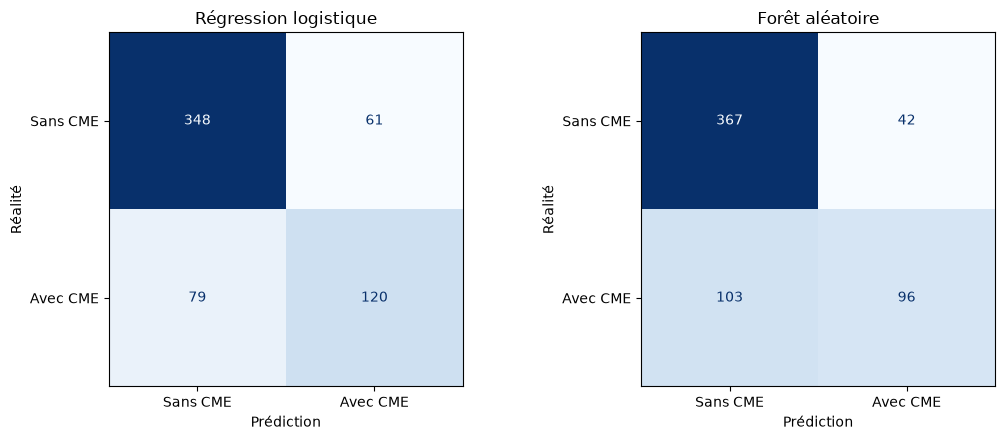

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (nom, res) in zip(axes, resultats.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, res["predictions"],
        display_labels=["Sans CME", "Avec CME"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(nom)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réalité")

plt.tight_layout()
plt.savefig("graphiques/matrices_confusion.png", dpi=130)
plt.show()

## 11. Courbes ROC

Une courbe qui s'éloigne de la diagonale indique un modèle qui sépare bien les deux
classes. La diagonale, c'est le hasard.

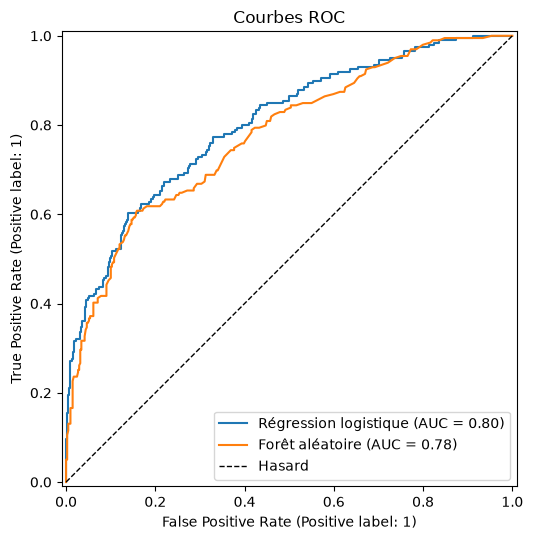

In [77]:
fig, ax = plt.subplots(figsize=(6, 5.5))

for nom, chaine in chaines.items():
    RocCurveDisplay.from_estimator(chaine, X_test, y_test, name=nom, ax=ax)

ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Hasard")
ax.set_title("Courbes ROC")
ax.legend()
plt.tight_layout()
plt.savefig("graphiques/courbes_roc.png", dpi=130)
plt.show()

## 12. Ce sur quoi le modèle s'appuie

Les coefficients de la régression logistique se lisent directement : un coefficient
positif augmente la probabilité de CME, un coefficient négatif la diminue. Plus il
est grand en valeur absolue, plus la variable pèse.

Les variables ayant été mises à la même échelle par le `StandardScaler`, leurs
coefficients sont comparables entre eux.

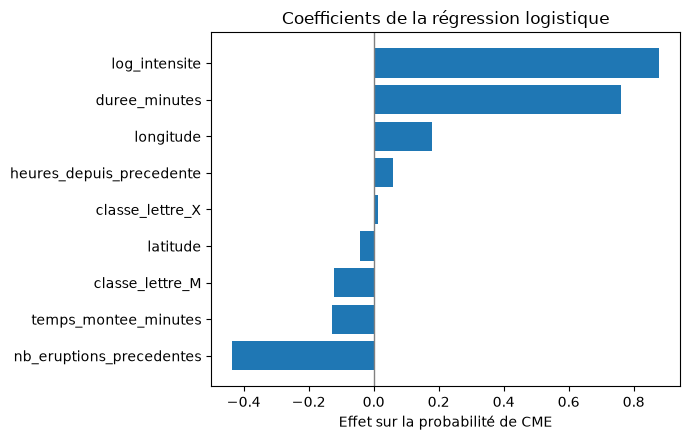

log_intensite               0.877
duree_minutes               0.760
nb_eruptions_precedentes   -0.435
longitude                   0.180
temps_montee_minutes       -0.127
classe_lettre_M            -0.121
heures_depuis_precedente    0.061
latitude                   -0.042
classe_lettre_X             0.013


In [78]:
chaine_lr = chaines["Régression logistique"]

noms = chaine_lr.named_steps["preprocessing"].get_feature_names_out()
noms = [nom.replace("num__", "").replace("cat__", "") for nom in noms]

coefficients = pd.Series(
    chaine_lr.named_steps["modele"].coef_[0], index=noms
).sort_values()

plt.figure(figsize=(7, 4.5))
plt.barh(coefficients.index, coefficients.values)
plt.axvline(0, color="grey", linewidth=1)
plt.title("Coefficients de la régression logistique")
plt.xlabel("Effet sur la probabilité de CME")
plt.tight_layout()
plt.savefig("graphiques/importances.png", dpi=130)
plt.show()

print(coefficients.sort_values(key=abs, ascending=False).round(3).to_string())

## 13. Ajuster le seuil de décision

Par défaut, une éruption est classée « avec CME » si sa probabilité dépasse 0,5. Ce
seuil n'a rien d'obligatoire : dans un contexte de surveillance, on peut l'abaisser
pour détecter plus de CME, en acceptant davantage de fausses alertes.

Limite à garder en tête : le seuil étant choisi en regardant le jeu de test, le
résultat obtenu à ce seuil est légèrement optimiste.

In [79]:
from sklearn.metrics import precision_score, recall_score

probas = resultats["Régression logistique"]["probabilites"]

for seuil in [0.3, 0.4, 0.5, 0.6]:
    predictions = (probas >= seuil).astype(int)
    precision = precision_score(y_test, predictions)
    rappel = recall_score(y_test, predictions)
    print(f"Seuil {seuil} : précision {precision:.2f}, rappel {rappel:.2f}")

Seuil 0.3 : précision 0.47, rappel 0.85
Seuil 0.4 : précision 0.55, rappel 0.71
Seuil 0.5 : précision 0.66, rappel 0.60
Seuil 0.6 : précision 0.72, rappel 0.45


## 14. Choisir et sauvegarder

**Modèle retenu : la régression logistique.** Meilleure AUC (0,80 contre 0,78), pas de
surapprentissage (justesse de 0,76 à l'entraînement, 0,77 au test, contre 0,998 et
0,76 pour la forêt), coefficients interprétables, et elle manque 79 CME là où la forêt
en manque 103.

**Seuil retenu : 0,4.** Dans un contexte de surveillance, laisser passer un CME coûte
plus cher qu'une fausse alerte. Abaisser le seuil de 0,5 à 0,4 fait passer le rappel
de 0,60 à 0,71, pour une précision de 0,55 : un peu plus d'une alerte sur deux est
justifiée. Descendre à 0,3 porterait le rappel à 0,85, mais avec moins d'une alerte
juste sur deux — au risque que les alertes ne soient plus prises au sérieux.

Le seuil n'est pas enregistré dans le modèle : c'est `predire.py` qui l'applique aux
probabilités.

In [80]:
MODELE_RETENU = "Régression logistique"
SEUIL = 0.4
CHEMIN_MODELE = "modele_cme.pkl"

chaine_finale = chaines[MODELE_RETENU]
joblib.dump(chaine_finale, CHEMIN_MODELE)

print(f"Modèle retenu : {MODELE_RETENU}")
print(f"AUC ROC       : {resultats[MODELE_RETENU]['auc']:.3f}")
print(f"Seuil         : {SEUIL}")
print(f"Enregistré dans {CHEMIN_MODELE} ({os.path.getsize(CHEMIN_MODELE) / 1024:.0f} Ko)")

Modèle retenu : Régression logistique
AUC ROC       : 0.801
Seuil         : 0.4
Enregistré dans modele_cme.pkl (4 Ko)


## 15. Vérification finale

On recharge le fichier et on vérifie qu'il produit exactement les mêmes prédictions.
Un modèle mal sauvegardé donnerait des résultats différents en production, sans
qu'aucune erreur ne le signale.

In [81]:
recharge = joblib.load(CHEMIN_MODELE)

identiques = (
    recharge.predict_proba(X_test)[:, 1] == chaine_finale.predict_proba(X_test)[:, 1]
).all()

print(f"Probabilités identiques après rechargement : {identiques}")

Probabilités identiques après rechargement : True
